# B3.1 — Le MLP spectre → fingerprint

**Objectif** (plan B, tâche B3.1) : un premier modèle appris, qui prédit le fingerprint de Morgan (2 048 bits) d'une molécule à partir de l'un de ses spectres. On classe ensuite les candidats de la fenêtre de masse par similarité de Tanimoto avec ce fingerprint prédit.

1. Les entrées (matrices de A) et les cibles (fingerprints du catalogue).
2. Contrôle du plan : le modèle doit sur-apprendre 1 000 spectres.
3. Entraînement sur `train_sample`, avec un early stopping sur 5 % de ses molécules.
4. Qualité du fingerprint prédit sur `dev` : Tanimoto, précision et rappel des bits.
5. MRR@25 sur `dev`, comparé à la baseline 0 (masse seule) et à l'oracle (vrai fingerprint).

**Split** : celui de A (`split.parquet`). `train_sample` ne contient que des molécules du split `train` (filtre `keep`), `dev` que des molécules `val` (filtre `query_ok`). Aucun spectre d'une molécule de `dev` ne sert à l'entraînement ni à l'early stopping.

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp

# Racine du dépôt : premier dossier parent qui contient pyproject.toml
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT / "src"))

from casmi.catalog import PROCESSED_DIR, load_catalog, mass_windows
from casmi.clean import load_clean_meta
from casmi.config import FP_SIZE, SEED
from casmi.fingerprints import load_catalog_fps
from casmi.mass import compute_neutral_masses
from casmi.matrices import load_matrices
from casmi.metrics import mrr_at_k, recall_at_k
from casmi.models.mlp import MODEL_PATH, TrainConfig, fingerprint_metrics, load_model, predict_proba, save_model, train_mlp

# Les fichiers de A (split, meta, matrices) et de B (catalogue, fingerprints) sont dans le même dossier
DATA = PROCESSED_DIR
print("Dossier des données :", DATA)


def style(ax):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e5e4e0", linewidth=0.8)
    ax.set_axisbelow(True)

Dossier des données : C:\Users\fanny\casmi_data\processed


## 1. Les entrées et les cibles

Les entrées sont les matrices de A (`load_matrices`) : le spectre biné (10 000 cases de 0,1 Da, intensités en racine carrée, norme 1), suivi des 31 features de métadonnées (adduct en *one-hot*). Elles restent creuses en mémoire et ne passent en dense que par batch.

La cible d'un spectre est le fingerprint de sa molécule, lu dans `catalog_fp.npy` à la ligne de son `inchikey14`.

In [2]:
X_sample, rows_sample, input_names = load_matrices("train_sample", directory=DATA)
X_dev, rows_dev, _ = load_matrices("dev", directory=DATA)

catalog = load_catalog()
fps = load_catalog_fps(mmap=True)
cat_of_key = pd.Series(catalog["cat_idx"].to_numpy(), index=catalog["inchikey14"].to_numpy())


def targets(keys):
    """Fingerprints (uint8) des molécules keys, dans l'ordre."""
    return np.asarray(fps[cat_of_key.loc[np.asarray(keys)].to_numpy()])


Y_sample, Y_dev = targets(rows_sample["inchikey14"]), targets(rows_dev["inchikey14"])

shared = set(rows_sample["inchikey14"]) & set(rows_dev["inchikey14"])
assert not shared, f"fuite : {len(shared)} molécules à la fois dans train_sample et dev"
print(f"train_sample : {X_sample.shape[0]:,} spectres, {rows_sample['inchikey14'].nunique():,} molécules")
print(f"dev          : {X_dev.shape[0]:,} spectres, {rows_dev['inchikey14'].nunique():,} molécules")
print(f"entrées : {X_sample.shape[1]:,} colonnes ({sum(n.startswith('bin_') for n in input_names):,} cases de spectre, "
      f"{sum(not n.startswith('bin_') for n in input_names)} features de métadonnées)")
print(f"cibles : {FP_SIZE} bits, {Y_sample.mean():.2%} de bits à 1 en moyenne")

train_sample : 200,000 spectres, 108,705 molécules
dev          : 18,899 spectres, 2,000 molécules
entrées : 10,031 colonnes (10,000 cases de spectre, 31 features de métadonnées)


cibles : 2048 bits, 2.24% de bits à 1 en moyenne


### Une validation interne pour l'early stopping

L'early stopping choisit l'époque à garder : c'est une forme d'apprentissage. S'il regardait `dev`, le score final sur `dev` serait un peu optimiste. On met donc de côté **5 % des molécules de `train_sample`** (toutes dans le split `train` de A), avec tous leurs spectres, et `dev` ne sert qu'à l'évaluation finale.

In [3]:
rng = np.random.default_rng(SEED)
molecules = np.sort(rows_sample["inchikey14"].unique())
stop_keys = rng.choice(molecules, size=len(molecules) // 20, replace=False)
is_stop = rows_sample["inchikey14"].isin(stop_keys).to_numpy()

X_train, Y_train = X_sample[~is_stop], Y_sample[~is_stop]
X_stop, Y_stop = X_sample[is_stop], Y_sample[is_stop]
print(f"entraînement : {X_train.shape[0]:,} spectres ({len(molecules) - len(stop_keys):,} molécules)")
print(f"early stopping : {X_stop.shape[0]:,} spectres ({len(stop_keys):,} molécules)")

entraînement : 189,661 spectres (103,270 molécules)
early stopping : 10,339 spectres (5,435 molécules)


## 2. Contrôle : sur-apprendre 1 000 spectres

Le plan le demande avant tout entraînement sérieux : sans dropout, un réseau assez grand doit apprendre par cœur un petit échantillon. Si la loss ne descend pas, il y a un bug (entrées et cibles mal alignées, gradient coupé…).

Il faut assez d'itérations : avec 100 époques (1 000 pas d'Adam), le Tanimoto n'atteignait que 0,34 ; avec 300 époques, le réseau apprend l'échantillon par cœur.

In [4]:
small = np.sort(rng.choice(X_train.shape[0], 1_000, replace=False))
config_small = TrainConfig(hidden=512, dropout=0.0, lr=1e-3, batch_size=100, max_epochs=300)
t0 = time.perf_counter()
model_small, history_small = train_mlp(X_train[small], Y_train[small], config=config_small, verbose=False)
fit = fingerprint_metrics(predict_proba(model_small, X_train[small]), Y_train[small])
print(f"{len(history_small)} époques en {time.perf_counter() - t0:.0f} s")
print(f"loss : {history_small[0]['train_loss']:.4f} à la 1re époque, {history_small[-1]['train_loss']:.5f} à la dernière")
print(f"Tanimoto sur ces 1 000 spectres : {fit['tanimoto']:.3f} (précision {fit['precision']:.3f}, rappel {fit['recall']:.3f})")

300 époques en 107 s
loss : 0.4158 à la 1re époque, 0.00143 à la dernière
Tanimoto sur ces 1 000 spectres : 0.998 (précision 0.999, rappel 0.998)


## 3. Entraînement sur `train_sample`

Architecture de départ du plan : `Linear(10 031, 2048) → ReLU → Dropout(0,2) → Linear(2048, 2048) → ReLU → Dropout(0,2) → Linear(2048, 2048)`, soit 2 048 logits, un par bit, et `BCEWithLogitsLoss` sans `pos_weight` (le déséquilibre des bits est une piste du sprint 4).

- Adam, taux d'apprentissage 10⁻³, batchs de 1 024 spectres (sur CPU, environ 2 minutes par époque).
- Early stopping : arrêt après 3 époques sans amélioration de la loss sur la validation interne, et on garde la meilleure époque.

Le modèle et son historique sont enregistrés hors git, dans `processed/models/`. Si le fichier existe déjà, il est rechargé au lieu d'être réentraîné (`RETRAIN = True` pour forcer).

In [5]:
RETRAIN = False
HISTORY_PATH = MODEL_PATH.with_name("mlp_history.csv")
config = TrainConfig(hidden=2048, dropout=0.2, lr=1e-3, batch_size=1024, max_epochs=25, patience=3, seed=0)

if RETRAIN or not MODEL_PATH.exists():
    t0 = time.perf_counter()
    model, history = train_mlp(X_train, Y_train, X_stop, Y_stop, config=config)
    print(f"Entraînement : {(time.perf_counter() - t0) / 60:.0f} min")
    save_model(model, config, MODEL_PATH)
    pd.DataFrame(history).to_csv(HISTORY_PATH, index=False)
else:
    model, config = load_model(MODEL_PATH)
    print("Modèle rechargé :", MODEL_PATH)

history = pd.read_csv(HISTORY_PATH)
best = history.loc[history["val_loss"].idxmin()]
print(f"{len(history)} époques, meilleure : {int(best['epoch'])} (loss de validation {best['val_loss']:.4f}, "
      f"Tanimoto {best['val_tanimoto']:.3f}), {history['seconds'].mean() / 60:.1f} min par époque")
print(config)

Modèle rechargé : C:\Users\fanny\casmi_data\processed\models\mlp.pt
20 époques, meilleure : 17 (loss de validation 0.0701, Tanimoto 0.258), 2.5 min par époque
TrainConfig(hidden=2048, dropout=0.2, lr=0.001, batch_size=1024, max_epochs=25, patience=3, pos_weight=None, seed=0, n_threads=12, train_monitor_size=20000, adduct_encoding='onehot')


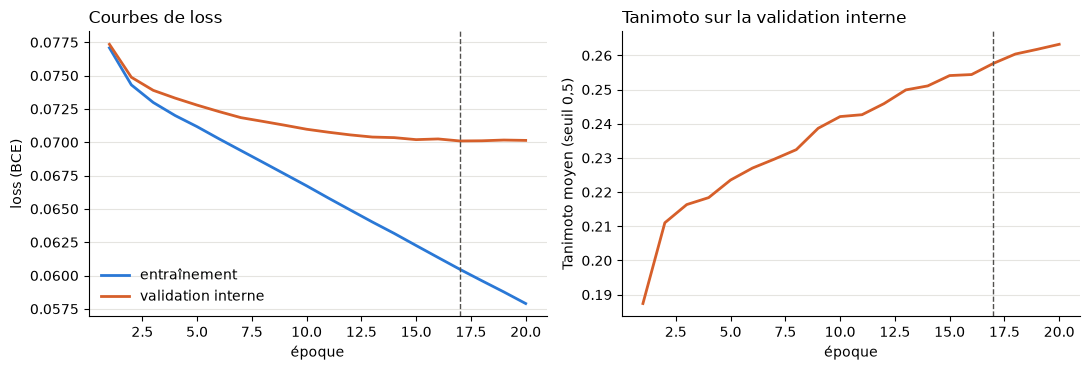

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
ax1.plot(history["epoch"], history["train_loss"], color="#2a78d6", linewidth=2, label="entraînement")
ax1.plot(history["epoch"], history["val_loss"], color="#d65f2a", linewidth=2, label="validation interne")
ax1.axvline(best["epoch"], color="#52514e", linestyle="--", linewidth=1)
ax1.set_xlabel("époque")
ax1.set_ylabel("loss (BCE)")
ax1.set_title("Courbes de loss", loc="left")
ax1.legend(frameon=False)
style(ax1)

ax2.plot(history["epoch"], history["val_tanimoto"], color="#d65f2a", linewidth=2)
ax2.axvline(best["epoch"], color="#52514e", linestyle="--", linewidth=1)
ax2.set_xlabel("époque")
ax2.set_ylabel("Tanimoto moyen (seuil 0,5)")
ax2.set_title("Tanimoto sur la validation interne", loc="left")
style(ax2)
plt.tight_layout()
plt.show()

## 4. Qualité du fingerprint prédit sur `dev`

Trois façons de mesurer, sur les 2 000 molécules `dev` que le modèle n'a jamais vues :
- **par spectre** : le fingerprint prédit à partir d'un seul spectre ;
- **par molécule** : la moyenne des probabilités prédites pour tous ses spectres (une première version de `aggregate_fps` de C) ;
- **référence naïve** : prédire pour toutes les molécules la fréquence de chaque bit dans le train. Un modèle utile doit faire nettement mieux.

Rappel (notebook 03) : seuls 2,25 % des bits sont à 1, donc l'exactitude n'a pas de sens ; on suit le Tanimoto, la précision et le rappel des bits à 1.

In [7]:
P_dev = predict_proba(model, X_dev)

# Agrégation par molécule : moyenne des probabilités de ses spectres
codes, dev_keys = pd.factorize(rows_dev["inchikey14"])
n_mol = len(dev_keys)
G = sp.csr_matrix((np.ones(len(codes), dtype=np.float32), (codes, np.arange(len(codes)))), shape=(n_mol, len(codes)))
P_mol = np.asarray(G @ P_dev) / np.bincount(codes)[:, None]
Y_mol = targets(dev_keys)

prior = np.tile(Y_train.mean(axis=0, dtype=np.float64), (n_mol, 1))
quality = pd.DataFrame({
    "MLP, par spectre": fingerprint_metrics(P_dev, Y_dev),
    "MLP, par molécule (moyenne)": fingerprint_metrics(P_mol, Y_mol),
    "référence : fréquence des bits": fingerprint_metrics(prior, Y_mol),
}).T
quality.round(3)

,tanimoto,precision,recall
"MLP, par spectre",0.257,0.747,0.281
"MLP, par molécule (moyenne)",0.260,0.805,0.276
référence : fréquence des bits,0.176,0.768,0.183


In [8]:
# Le seuil de 0,5 est arbitraire : Tanimoto par molécule selon le seuil
for t in (0.2, 0.3, 0.4, 0.5):
    m = fingerprint_metrics(P_mol, Y_mol, threshold=t)
    print(f"seuil {t:.1f} : Tanimoto {m['tanimoto']:.3f}, précision {m['precision']:.3f}, rappel {m['recall']:.3f}")

seuil 0.2 : Tanimoto 0.316, précision 0.548, rappel 0.422
seuil 0.3 : Tanimoto 0.305, précision 0.673, rappel 0.356
seuil 0.4 : Tanimoto 0.284, précision 0.751, rappel 0.312
seuil 0.5 : Tanimoto 0.260, précision 0.805, rappel 0.276


### Par bibliothèque

Le test visible est entièrement fait de spectres d'enveda-180 (timsTOF), voir `notebooks/A/03_train_vs_test.ipynb`. On regarde donc le Tanimoto par spectre selon la bibliothèque d'origine.

In [9]:
meta_dev = load_clean_meta(DATA / "meta.parquet").set_index("row_id").loc[rows_dev["row_id"]].reset_index()

pred, true = P_dev >= 0.5, Y_dev > 0
tanimoto_spectre = (pred & true).sum(axis=1) / np.maximum((pred | true).sum(axis=1), 1)
by_lib = (pd.DataFrame({"bibliothèque": meta_dev["ingest_lib"].astype(str), "tanimoto": tanimoto_spectre})
          .groupby("bibliothèque")["tanimoto"].agg(spectres="size", tanimoto_moyen="mean")
          .sort_values("spectres", ascending=False))
by_lib.round(3)

,spectres,tanimoto_moyen
bibliothèque,,
enveda-180,8555,0.243
pluskal_ms2,3967,0.244
riken,2973,0.239
gnps,1528,0.297
massbank,660,0.314
mona,595,0.272
spectraverse,326,0.569
msdial,255,0.312
enveda-np-examples,18,0.198


## 5. MRR@25 sur `dev` (évaluation provisoire)

C n'a pas encore livré `evaluate`, `aggregate_fps` ni `tanimoto_scores`. On écrit ici une version provisoire qui suit le contrat d'interfaces, **à remplacer par `evaluate(scorer)` dès que C l'aura livré** :
- une masse neutre par molécule : la médiane des masses de ses spectres (`compute_neutral_masses`), comme proposé en B1.3 ;
- les candidats : la fenêtre de 10 ppm dans le catalogue « monde fermé » (train et validation) ;
- un score par candidat, puis les 25 meilleurs, et `mrr_at_k` / `recall_at_k` de C.

Quatre scorers :
- **baseline 0** : −|erreur de masse| (le plancher) ;
- **MLP, Tanimoto continu** : Tanimoto entre les probabilités prédites p et le fingerprint c du candidat, Σpc / (Σp + Σc − Σpc), sans seuil ;
- **MLP, seuil 0,5** : Tanimoto classique, après seuillage de la prédiction ;
- **oracle** : Tanimoto avec le vrai fingerprint (le plafond de cette représentation).

En cas d'égalité, l'ordre du catalogue départage (c'est le cas des isomères pour la baseline 0, et des fingerprints identiques pour l'oracle).

In [10]:
mol_mass = pd.Series(compute_neutral_masses(meta_dev)).groupby(codes).median().to_numpy()
masses = catalog["exact_mass"].to_numpy()
cat_keys = catalog["inchikey14"].to_numpy()
lo, hi = mass_windows(mol_mass, masses, ppm=10)
true_keys = list(dev_keys)
in_window = np.array([cat_of_key[k] in range(a, b) for k, a, b in zip(true_keys, lo, hi)])
print(f"Candidats par molécule : médiane {np.median(hi - lo):.0f}, 90e centile {np.percentile(hi - lo, 90):.0f}")
print(f"Rappel du filtre (vraie molécule dans la fenêtre) : {in_window.mean():.1%}")


def tanimoto(p, C):
    """Tanimoto (continu si p est une probabilité) entre p (n_bits,) et chaque ligne de C (n, n_bits)."""
    common = C @ p
    return common / (C.sum(axis=1) + p.sum() - common)


def rank(scorer, k=25):
    """Les k meilleurs inchikey14 de chaque molécule dev selon scorer(i, cand) (plus grand = plus probable)."""
    ranked = []
    for i, (a, b) in enumerate(zip(lo, hi)):
        cand = np.arange(a, b)
        scores = scorer(i, cand) if len(cand) else np.empty(0)
        ranked.append(cat_keys[cand[np.argsort(-scores, kind="stable")[:k]]].tolist())
    return ranked


scorers = {
    "baseline 0 : masse seule": lambda i, c: -np.abs(masses[c] - mol_mass[i]),
    "MLP, Tanimoto continu": lambda i, c: tanimoto(P_mol[i], fps[c].astype(np.float32)),
    "MLP, seuil 0,5": lambda i, c: tanimoto((P_mol[i] >= 0.5).astype(np.float32), fps[c].astype(np.float32)),
    "oracle : vrai fingerprint": lambda i, c: tanimoto(Y_mol[i].astype(np.float32), fps[c].astype(np.float32)),
}
results = {}
for name, scorer in scorers.items():
    ranked = rank(scorer)
    results[name] = {
        "MRR@25": mrr_at_k(true_keys, ranked, k=25),
        "rappel@1": recall_at_k(true_keys, ranked, 1),
        "rappel@5": recall_at_k(true_keys, ranked, 5),
        "rappel@25": recall_at_k(true_keys, ranked, 25),
    }
results = pd.DataFrame(results).T
results.round(3)

Candidats par molécule : médiane 60, 90e centile 204
Rappel du filtre (vraie molécule dans la fenêtre) : 98.7%


,MRR@25,rappel@1,rappel@5,rappel@25
baseline 0 : masse seule,0.222,0.114,0.332,0.660
"MLP, Tanimoto continu",0.338,0.218,0.471,0.764
"MLP, seuil 0,5",0.256,0.152,0.359,0.668
oracle : vrai fingerprint,0.981,0.978,0.986,0.987


## Conclusions

**1. Le pipeline fonctionne de bout en bout, sans fuite.** Le split de A est respecté : aucune molécule n'est à la fois dans `train_sample` et dans `dev`, et l'early stopping n'utilise que 5 % des molécules de `train_sample`. Sans dropout, le réseau apprend par cœur 1 000 spectres (Tanimoto proche de 1), donc les entrées et les cibles sont bien alignées.

**2. L'entraînement.** 20 époques en 50 min sur CPU (2,5 min par époque) ; la meilleure est la 17e. Dès l'époque 15, la loss de validation plafonne à 0,070 alors que celle d'entraînement continue de baisser (0,058 à la fin) : le modèle commence à sur-apprendre. Il ne voit que 190 000 spectres, environ 8 % du train : utiliser tout le train est la piste la plus directe.

**3. Le fingerprint prédit reste approximatif.** Sur `dev`, le Tanimoto moyen vaut 0,26 (seuil de 0,5), contre 0,18 pour la référence naïve qui prédit la fréquence de chaque bit. Le modèle est prudent : quand il prédit un bit à 1, il a raison 8 fois sur 10 (précision 0,80), mais il ne retrouve que 28 % des bits à 1 (rappel). Un seuil de 0,2 donne un meilleur Tanimoto (0,32). Moyenner les spectres d'une molécule n'aide presque pas (0,257 par spectre, 0,260 par molécule). Sur enveda-180, la bibliothèque dont vient le test, le Tanimoto par spectre vaut 0,24, un peu sous la moyenne.

**4. Le MLP bat la baseline 0, loin de l'oracle.**

| scorer | MRR@25 | rappel@1 | rappel@25 |
|---|---|---|---|
| baseline 0 : masse seule | 0,222 | 11,4 % | 66,0 % |
| MLP, Tanimoto continu | **0,338** | **21,8 %** | **76,4 %** |
| MLP, seuil 0,5 | 0,256 | 15,2 % | 66,8 % |
| oracle : vrai fingerprint | 0,981 | 97,8 % | 98,7 % |

- Le **Tanimoto continu**, calculé sur les probabilités, classe nettement mieux que le Tanimoto après seuillage : c'est la version à proposer à C pour `tanimoto_scores`.
- L'écart avec l'oracle montre que la marge est dans la prédiction du fingerprint, pas dans le classement.
- Le score du MLP ignore la masse à l'intérieur de la fenêtre de 10 ppm : un candidat d'une autre formule brute, mais de structure proche, peut passer devant la bonne réponse. Combiner les deux scores devrait aider (fusion de scores, tâche de C au sprint 4).

**5. Pistes pour le sprint 4**, une modification à la fois : entraîner sur tout le train (avec `make_loader` de A) ; `pos_weight` ou *focal loss*, puisque le modèle sous-prédit les bits à 1 ; fingerprint à comptage.

**À reprendre** quand C aura livré : remplacer l'évaluation provisoire de la section 5 par `evaluate(scorer)`, et ajouter le résultat dans `reports/results.csv` avec `log_result`.